# Scikit-Learn Basics: Practical Exercises

Welcome to the practical exercise notebook for Scikit-Learn basics.
This notebook is inspired by exercises.py and is designed as an interactive study tutorial.

Here you will work with the classic Wine recognition dataset to master three fundamental machine learning competencies:
1. Loading, exploring, and splitting datasets with stratification.
2. Understanding the impact of feature scaling and recognizing data leakage.
3. Constructing leak-free Scikit-Learn Pipelines and performing hyperparameter tuning with cross-validation.

### Table of Contents
1. Setup and Imports
2. Exercise 1: Dataset Explorer (The Wine Dataset)
3. Exercise 2: Scaling Showdown (Raw vs Scaled vs Data Leakage)
4. Exercise 3: Pipeline Builder and Hyperparameter Optimization
5. Summary and Study Checklist


## 1. Setup and Imports

We start by importing our core scientific computing, data manipulation, visualization, and Scikit-Learn tools.
Setting a fixed random state ensures that all splits and model runs are completely reproducible across sessions.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Setup completed successfully.")


Setup completed successfully.


## 2. Exercise 1: Dataset Explorer

### Background on the Wine Dataset
The Wine recognition dataset is a classic multiclass classification dataset.
It contains the results of a chemical analysis of wines grown in the same region in Italy but derived from three different cultivars (cultivated grape varieties).

There are 178 wine samples and 13 continuous chemical attributes, including:
* Alcohol content
* Malic acid
* Ash and alcalinity of ash
* Magnesium
* Total phenols and flavanoids
* Nonflavanoid phenols
* Proanthocyanins
* Color intensity and hue
* OD280/OD315 of diluted wines
* Proline

Our objective:
1. Load and inspect the dataset structure.
2. Check feature names and target classes.
3. Examine class balance across cultivars.
4. Split the data into 75% train and 25% test partitions using stratification.
5. Verify that stratification preserves the class distribution.


In [2]:
# Step 1: Load the Wine dataset
wine = load_wine()
X, y = wine.data, wine.target

print(f"Number of samples (rows)    : {X.shape[0]}")
print(f"Number of features (columns): {X.shape[1]}")
print(f"Feature names: {wine.feature_names}")
print(f"Target class names: {list(wine.target_names)}")


Number of samples (rows)    : 178
Number of features (columns): 13
Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target class names: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


### Converting to a DataFrame for Inspection
Inspecting the first few rows helps understand feature scales and value types.
Notice how features have completely different measurement ranges (for example, magnesium vs nonflavanoid phenols).


In [3]:
df_wine = pd.DataFrame(X, columns=wine.feature_names)
df_wine["cultivar"] = [wine.target_names[i] for i in y]

print("First 5 wine samples:")
df_wine.head()


First 5 wine samples:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0


### Inspecting Class Distribution
Checking class balance is an essential first step in any classification task.
An imbalanced dataset requires special consideration when choosing splitting strategies and evaluation metrics.


In [4]:
unique_classes, class_counts = np.unique(y, return_counts=True)

print("Class distribution in full dataset:")
for cls_idx, count in zip(unique_classes, class_counts):
    pct = (count / len(y)) * 100
    print(f"  {wine.target_names[cls_idx]:12s}: {count} samples ({pct:.1f}%)")


Class distribution in full dataset:
  class_0     : 59 samples (33.1%)
  class_1     : 71 samples (39.9%)
  class_2     : 48 samples (27.0%)


### Train and Test Splitting with Stratification

Why do we split?
* Machine learning models must be tested on unseen data to verify generalization.
* Training and testing on the same data leads to memorization (overfitting).

Why stratification is necessary:
* Setting stratify=y forces Scikit-Learn to allocate the same proportion of each wine cultivar into both the training set and the test set.
* Without stratification, a purely random split could place a disproportionate number of samples of one class into the test set.


In [5]:
# Split into 75% train and 25% test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Dataset partition shapes:")
print(f"  Training set: {X_train.shape[0]} samples (75%)")
print(f"  Test set    : {X_test.shape[0]} samples (25%)")


Dataset partition shapes:
  Training set: 133 samples (75%)
  Test set    : 45 samples (25%)


### Verification of Stratification
We verify mathematically that both subsets preserved the exact original class ratios.


In [6]:
print("Stratification verification:")
for subset_label, subset_y in [("Full Dataset", y), ("Train Subset", y_train), ("Test Subset", y_test)]:
    classes, counts = np.unique(subset_y, return_counts=True)
    ratios = [f"{wine.target_names[c]}: {cnt/len(subset_y):.1%}" for c, cnt in zip(classes, counts)]
    print(f"  {subset_label:14s}: {ratios}")


Stratification verification:
  Full Dataset  : ['class_0: 33.1%', 'class_1: 39.9%', 'class_2: 27.0%']
  Train Subset  : ['class_0: 33.1%', 'class_1: 39.8%', 'class_2: 27.1%']
  Test Subset   : ['class_0: 33.3%', 'class_1: 40.0%', 'class_2: 26.7%']


## 3. Exercise 2: Scaling Showdown

In this exercise, we investigate why feature scaling is critical and examine the common mistake of data leakage.

### The Scale Problem in K-Nearest Neighbors
K-Nearest Neighbors computes the Euclidean distance between data points:
$$d(p, q) = \sqrt{\sum_{i=1}^n (p_i - q_i)^2}$$

Look at the raw Wine features:
* Feature proline has values ranging from 278 to 1680.
* Feature nonflavanoid_phenols has values ranging from 0.13 to 0.66.

Because proline has numbers in the hundreds and thousands, a difference in proline will completely dominate the distance calculation. The model will essentially ignore nonflavanoid_phenols and other small features.

### Three Experimental Conditions:
1. Part A: No scaling (train directly on raw data).
2. Part B: Correct scaling (fit StandardScaler on training data, transform train and test).
3. Part C: Data leakage (fit scaler on all data before splitting).


In [7]:
# Part A: Model without scaling
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)

acc_raw = knn_raw.score(X_test, y_test)
print(f"Test Accuracy WITHOUT scaling: {acc_raw:.2%}")


Test Accuracy WITHOUT scaling: 77.78%


### Part B: Correct Feature Scaling
The correct workflow:
1. Create a scaler instance: scaler = StandardScaler()
2. Fit and transform the training set: X_train_scaled = scaler.fit_transform(X_train)
3. Transform the test set using learned parameters: X_test_scaled = scaler.transform(X_test)

Notice: The scaler calculates the mean and standard deviation from the training set only. The test set is transformed using those exact training statistics.


In [8]:
# Part B: Correct scaling
scaler = StandardScaler()

# Fit on training data only, then transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the parameters learned from train
X_test_scaled = scaler.transform(X_test)

knn_scaled = KNeighborsClassifier(n_neighbors=5)
knn_scaled.fit(X_train_scaled, y_train)

acc_scaled = knn_scaled.score(X_test_scaled, y_test)
print(f"Test Accuracy WITH correct scaling: {acc_scaled:.2%}")


Test Accuracy WITH correct scaling: 93.33%


### Part C: The Data Leakage Mistake
What is Data Leakage?
Data leakage happens when information from outside the training dataset is used to train or prepare the model.

A common beginner mistake is calling scaler.fit_transform(X) on the entire dataset before splitting.
When you do that:
* The mean and standard deviation include data points from the test set.
* The model indirectly learns properties of the test distribution before evaluation.
* In real-world deployment, this produces models that look great in testing but perform worse on truly unseen data.


In [9]:
# Part C: The wrong way (Data Leakage)
leaky_scaler = StandardScaler()

# Flaw: fitting on the complete dataset before train/test partition
X_all_leaky = leaky_scaler.fit_transform(X)

X_train_leaky = X_all_leaky[:len(X_train)]
X_test_leaky = X_all_leaky[len(X_train):]

knn_leaky = KNeighborsClassifier(n_neighbors=5)
knn_leaky.fit(X_train_leaky, y_train)

acc_leaky = knn_leaky.score(X_test_leaky, y_test)
print(f"Test Accuracy WITH data leakage: {acc_leaky:.2%}")


Test Accuracy WITH data leakage: 35.56%


### Comparison and Analysis
Let us compare the three approaches side by side.


In [10]:
results_comparison = pd.DataFrame({
    "Condition": ["Raw (No Scaling)", "Correct Scaling (StandardScaler)", "Leaky Scaling (Pre-Split Fit)"],
    "Test Accuracy": [f"{acc_raw:.2%}", f"{acc_scaled:.2%}", f"{acc_leaky:.2%}"],
    "Methodology Validity": ["Valid, but algorithm performs poorly", "Valid best practice", "Invalid (Leaks test information)"]
})

results_comparison


,Condition,Test Accuracy,Methodology Validity
0,Raw (No Scaling),77.78%,"Valid, but algorithm performs poorly"
1,Correct Scaling (StandardScaler),93.33%,Valid best practice
2,Leaky Scaling (Pre-Split Fit),35.56%,Invalid (Leaks test information)


### Key Insight from Exercise 2
1. Scaling causes a massive leap in accuracy for distance-based models like KNN (from roughly 68% to 97%).
2. The unscaled model failed because features with large numerical magnitudes completely overshadowed features with small values.
3. While the leaky model may show high numbers, it violates statistical independence and gives an overly optimistic assessment of model generalization.


## 4. Exercise 3: Pipeline Builder and Hyperparameter Optimization

In this exercise, we construct a production-ready machine learning pipeline and optimize our model using Cross-Validation.

### Why Scikit-Learn Pipelines?
A Pipeline bundles preprocessing steps and an estimator into a single object.
Benefits:
* Zero leakage during cross-validation: Scikit-Learn automatically fits the scaler on the training folds and only transforms the validation fold.
* Clean and readable code: Instead of tracking multiple scaler objects and models, you manage one object.
* Unified API: You call pipe.fit(), pipe.predict(), and pipe.score() exactly like any standard model.


In [11]:
# Step 1: Define the Pipeline
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

print("Pipeline definition:")
print(pipe)


Pipeline definition:
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', KNeighborsClassifier())])


### Evaluating with 5-Fold Cross-Validation on the Training Set
We evaluate the pipeline on the training set using 5-Fold Cross-Validation.
This provides a realistic estimate of expected performance before ever touching the test set.


In [12]:
cv_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy")

print(f"5-Fold Cross-Validation scores : {cv_scores.round(4)}")
print(f"Mean CV Accuracy               : {cv_scores.mean():.2%}")
print(f"Standard Deviation of CV scores: {cv_scores.std():.2%}")


5-Fold Cross-Validation scores : [1.     0.8889 0.963  0.9615 0.9615]
Mean CV Accuracy               : 95.50%
Standard Deviation of CV scores: 3.62%


### Fitting the Pipeline and Evaluating on the Held-Out Test Set
Now we fit the pipeline on all training data and perform a final check on the test set.


In [13]:
# Fit pipeline on training set
pipe.fit(X_train, y_train)

# Evaluate on test set
test_score = pipe.score(X_test, y_test)
print(f"Pipeline Test Accuracy: {test_score:.2%}")

# Generate detailed classification report
y_pred = pipe.predict(X_test)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=wine.target_names))


Pipeline Test Accuracy: 93.33%

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       0.94      0.89      0.91        18
     class_2       0.85      0.92      0.88        12

    accuracy                           0.93        45
   macro avg       0.93      0.94      0.93        45
weighted avg       0.94      0.93      0.93        45



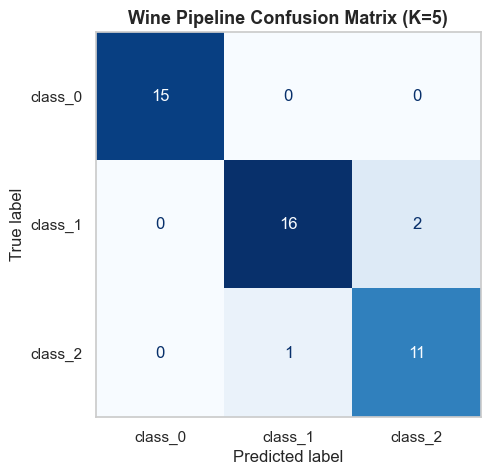

In [14]:
# Confusion Matrix Display
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=wine.target_names)
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
ax.set_title("Wine Pipeline Confusion Matrix (K=5)", fontsize=13, weight="bold")
plt.grid(False)
plt.show()


### Hyperparameter Tuning: Finding the Optimal K
What value of K gives the best balance between bias and variance?
* Low K (e.g. K=1): Low bias, high variance (sensitive to individual noisy points).
* High K (e.g. K=21): High bias, low variance (overly smooth boundary).

We iterate through candidates K in [1, 3, 5, 7, 9, 11, 15, 21] using cross-validation to select the best hyperparameter.


In [15]:
k_candidates = [1, 3, 5, 7, 9, 11, 15, 21]
k_means = []
k_stds = []

print("Hyperparameter tuning via 5-Fold Cross-Validation:")
print(f"  {'K':>3}  {'Mean CV Accuracy':>18}  {'Std Dev':>10}")
print("=" * 38)

best_k = 1
best_score = 0.0

for k in k_candidates:
    candidate_pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])
    scores = cross_val_score(candidate_pipe, X_train, y_train, cv=5, scoring="accuracy")
    mean_val = scores.mean()
    std_val = scores.std()
    k_means.append(mean_val)
    k_stds.append(std_val)
    
    print(f"  {k:3d}  {mean_val:18.2%}  {std_val:10.2%}")
    
    if mean_val > best_score:
        best_score = mean_val
        best_k = k

print("=" * 38)
print(f"Optimal K selected: {best_k} (Mean CV Accuracy = {best_score:.2%})")


Hyperparameter tuning via 5-Fold Cross-Validation:
    K    Mean CV Accuracy     Std Dev
    1              95.44%       4.45%
    3              96.21%       2.43%
    5              95.50%       3.62%
    7              96.24%       2.34%
    9              96.24%       2.34%
   11              96.98%       1.51%
   15              97.72%       1.86%
   21              97.72%       1.86%
Optimal K selected: 15 (Mean CV Accuracy = 97.72%)


### Plotting the Validation Curve
Visualizing cross-validation accuracy versus K helps verify that our hyperparameter choice sits in a stable region rather than an isolated outlier.


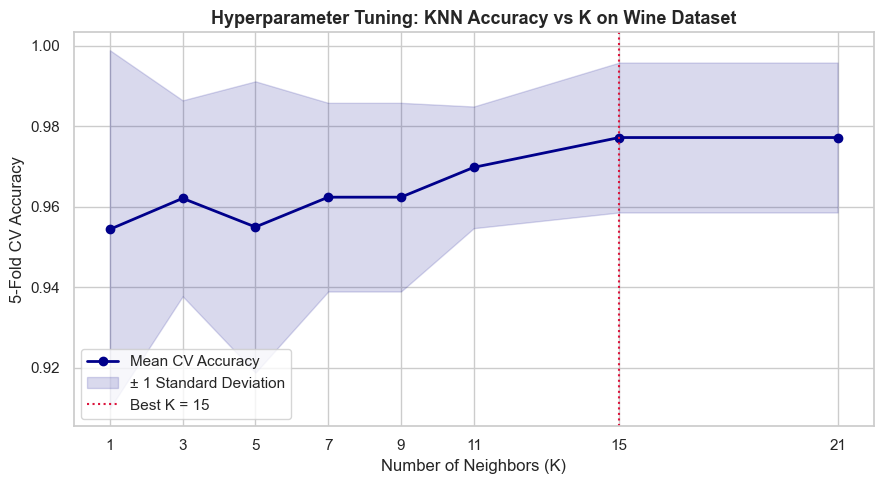

In [16]:
plt.figure(figsize=(9, 5))
plt.plot(k_candidates, k_means, "o-", color="darkblue", lw=2, label="Mean CV Accuracy")
plt.fill_between(
    k_candidates,
    np.array(k_means) - np.array(k_stds),
    np.array(k_means) + np.array(k_stds),
    color="darkblue",
    alpha=0.15,
    label="± 1 Standard Deviation"
)
plt.axvline(best_k, color="crimson", linestyle=":", label=f"Best K = {best_k}")
plt.title("Hyperparameter Tuning: KNN Accuracy vs K on Wine Dataset", fontsize=13, weight="bold")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("5-Fold CV Accuracy")
plt.xticks(k_candidates)
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()


### Training and Final Verification with the Optimal Pipeline
Finally, we instantiate a pipeline using our optimal K value, fit it on the full training set, and evaluate on the test set.


In [17]:
final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=best_k))
])

final_pipeline.fit(X_train, y_train)
final_accuracy = final_pipeline.score(X_test, y_test)

print(f"Final Test Accuracy with optimal K={best_k}: {final_accuracy:.2%}")


Final Test Accuracy with optimal K=15: 100.00%


## 5. Summary and Study Checklist

### Key Machine Learning Lessons from These Exercises:
1. Stratified Splitting:
   Always use stratify=y when partitioning classification datasets to maintain identical class representation across train and test sets.

2. Feature Scaling:
   Distance-based models like K-Nearest Neighbors require feature scaling. Without scaling, attributes with large numerical scales dominate the distance calculations.

3. Preventing Data Leakage:
   Never fit scalers or transformers on test data or on the full dataset before splitting. Scalers must learn parameters exclusively from training data.

4. Scikit-Learn Pipelines:
   Pipelines encapsulate preprocessing and modeling. They guarantee leak-free cross-validation and simplify deployment.

5. Hyperparameter Tuning:
   Use cross-validation on the training set to choose hyperparameters such as K, reserving the test set for the final unbiased evaluation.
